saved the figure
saved the figure


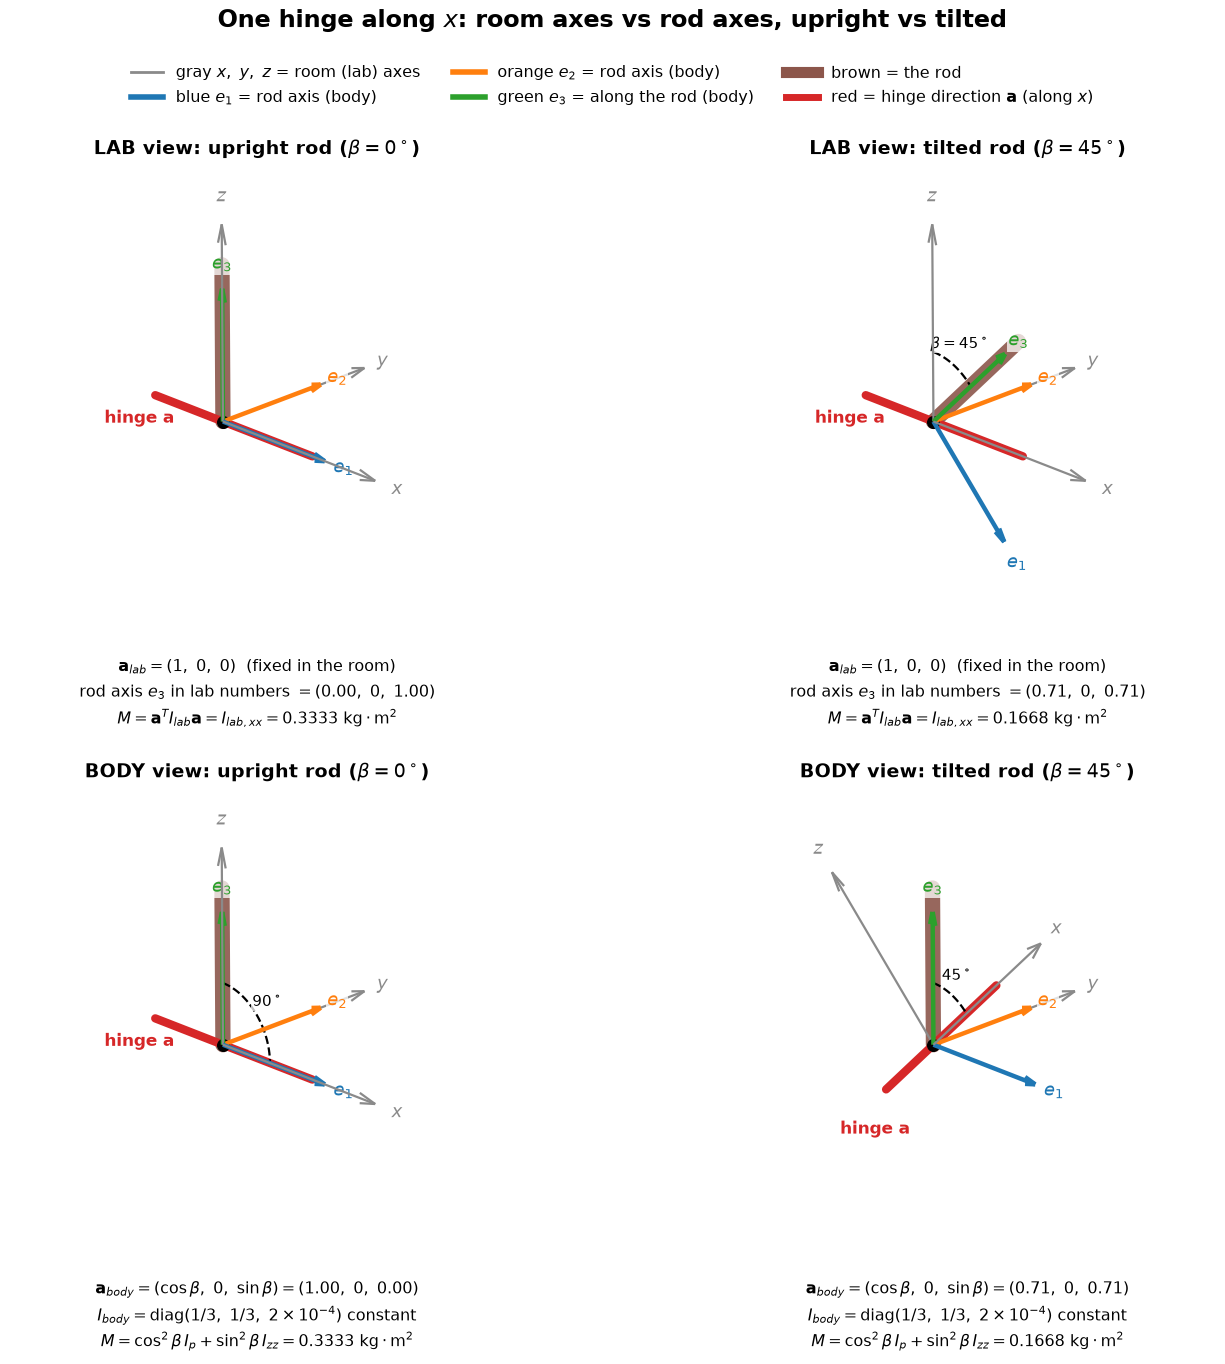

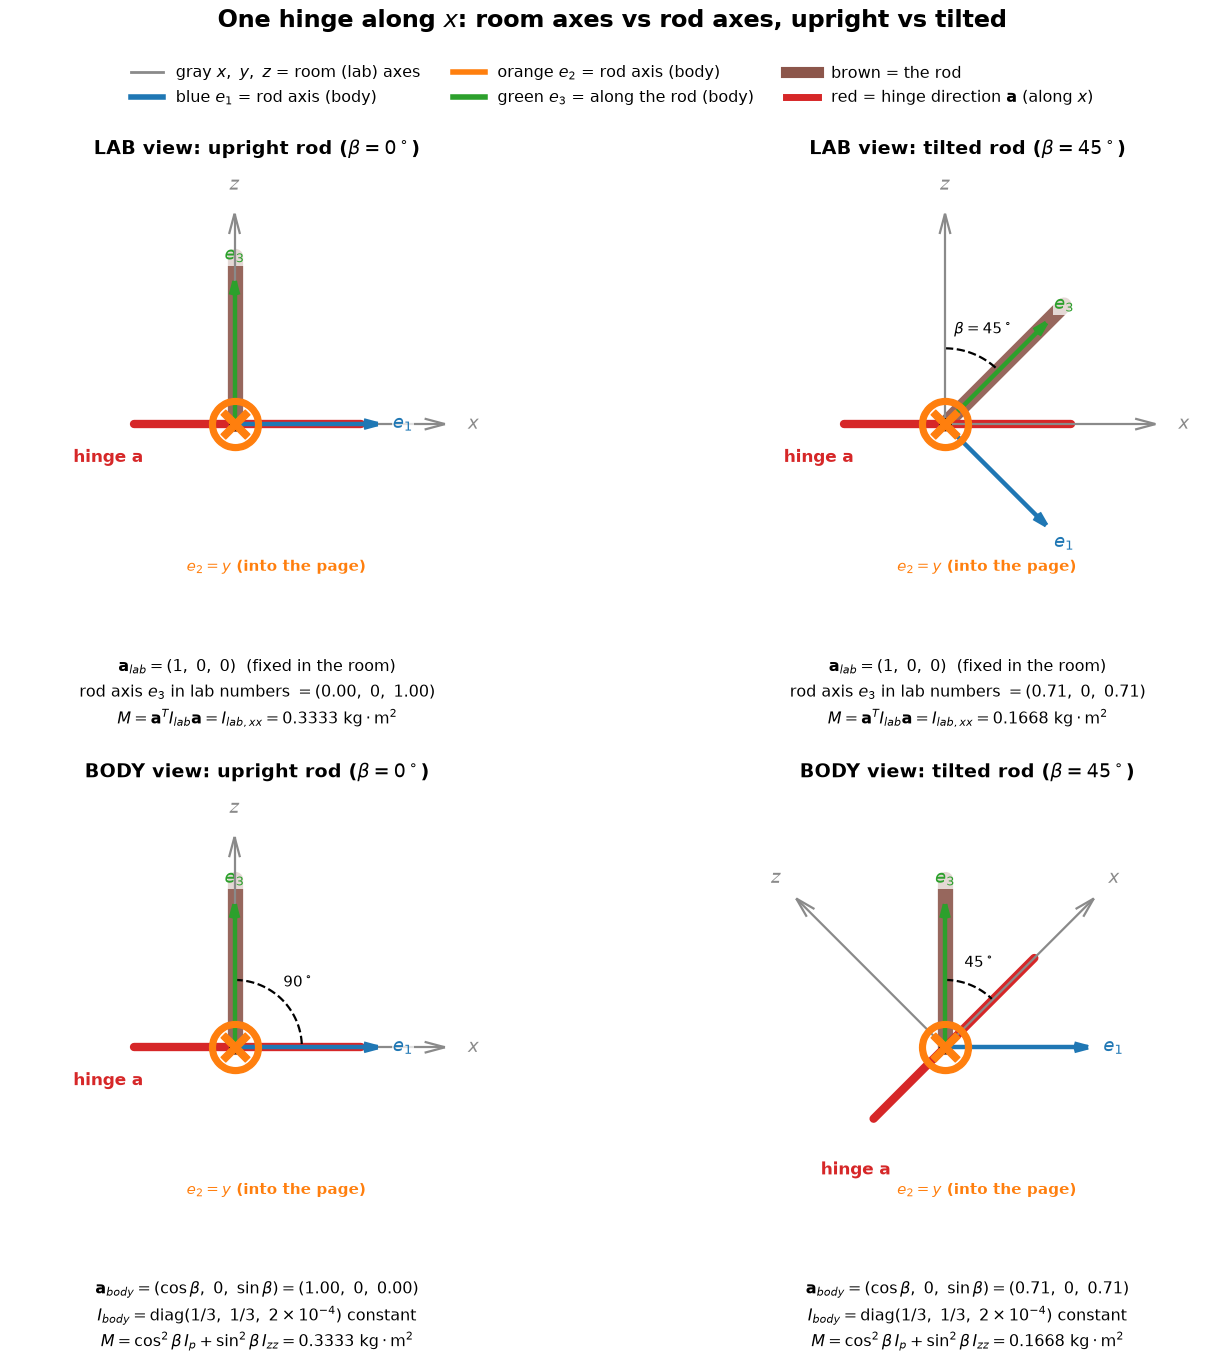

In [4]:
# =============================================================================
# One hinge along x: lab view vs body view, upright rod vs tilted rod
# =============================================================================
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.lines import Line2D  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# -----------------------------------------------------------------------------
# STEP 1: the rod and the hinge
# What we have : rod m = 1 kg, L = 1 m, r = 0.02 m, hinge at one end along x
#                I_p = m L^2 / 12 + m (L/2)^2 = 1/3 kg m^2 (across the rod)
#                I_zz = m r^2 / 2 = 2e-4 kg m^2 (along the rod)
# What we want : the same picture in lab axes (x, y, z) and body axes (e1, e2, e3)
# Why          : to see that tilting moves the rod in the lab view, and moves
#                the hinge in the body view
# -----------------------------------------------------------------------------
IP = 1.0 / 3.0
IZZ = 2.0e-4
I_BODY = np.diag([IP, IP, IZZ])
TILTS_DEG = [0.0, 45.0]

# colors
GRAY = "#8a8a8a"
BLUE = "#1f77b4"
ORANGE = "#ff7f0e"
GREEN = "#2ca02c"
BROWN = "#8c564b"
RED = "#d62728"
E_COLORS = [BLUE, ORANGE, GREEN]


# -----------------------------------------------------------------------------
# STEP 2: rotation matrix of the tilt (about y, rod swings from z toward x)
# What we have : tilt angle beta
# What we want : R = [e1 e2 e3], columns = body axes written in lab coordinates
#                R = [[cos b, 0, sin b], [0, 1, 0], [-sin b, 0, cos b]]
#                e1 = (cos b, 0, -sin b), e2 = (0, 1, 0), e3 = (sin b, 0, cos b)
# Why          : R turns body numbers into lab numbers, R^T does the reverse
# -----------------------------------------------------------------------------
def Ry(b):
    c, s = np.cos(b), np.sin(b)
    return np.array([[c, 0.0, s], [0.0, 1.0, 0.0], [-s, 0.0, c]])


# -----------------------------------------------------------------------------
# STEP 3: drawing helpers
# What we have : 3D axes
# What we want : arrows, labels, angle arcs
# Why          : reuse the same drawing for the four panels
# -----------------------------------------------------------------------------
def arrow(ax, v, color, lw, origin=(0.0, 0.0, 0.0)):
    ax.quiver(origin[0], origin[1], origin[2], v[0], v[1], v[2], color=color,
              linewidth=lw, arrow_length_ratio=0.10)


def line(ax, p0, p1, color, lw, alpha=1.0):
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], [p0[2], p1[2]], color=color,
            linewidth=lw, alpha=alpha, solid_capstyle="round")


def label(ax, p, text, color, size=13):
    ax.text(p[0], p[1], p[2], text, color=color, fontsize=size, fontweight="bold",
            ha="center", va="center",
            bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=0.8))


def arc(ax, u, v, radius, color="black"):
    """dashed arc from unit vector u to unit vector v, returns the angle in deg."""
    ang = np.arccos(np.clip(u @ v, -1.0, 1.0))
    w = v - (u @ v) * u
    w = w / np.linalg.norm(w)
    t = np.linspace(0.0, ang, 40)
    pts = np.array([radius * (np.cos(k) * u + np.sin(k) * w) for k in t])
    ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], color=color, linewidth=1.6,
            linestyle="--")
    mid = radius * 1.35 * (np.cos(ang / 2) * u + np.sin(ang / 2) * w)
    return np.degrees(ang), mid


# -----------------------------------------------------------------------------
# STEP 4: one panel
# What we have : view = "lab" or "body", tilt beta
# What we want : room axes x, y, z (gray), rod axes e1, e2, e3 (colors), rod, hinge a
# Why          : lab view: rod axes move, room axes fixed
#                body view: rod axes fixed, room axes (and the hinge) move
# -----------------------------------------------------------------------------
def draw_panel(ax, view, beta_deg, elev, azim, along_y):
    b = np.radians(beta_deg)
    R = Ry(b)
    x_hat = np.array([1.0, 0.0, 0.0])
    z_hat = np.array([0.0, 0.0, 1.0])

    if view == "lab":
        e_axes = [R[:, 0], R[:, 1], R[:, 2]]          # e1, e2, e3 in lab numbers
        room = [np.eye(3)[:, 0], np.eye(3)[:, 1], np.eye(3)[:, 2]]
        a = x_hat                                      # a_lab
    else:
        e_axes = [np.eye(3)[:, 0], np.eye(3)[:, 1], np.eye(3)[:, 2]]
        room = [R.T[:, 0], R.T[:, 1], R.T[:, 2]]       # x, y, z in body numbers
        a = R.T @ x_hat                                # a_body
    rod_dir = e_axes[2]

    # room axes (gray, long, thin)
    for v, name in zip(room, ["$x$", "$y$", "$z$"]):
        if along_y and name == "$y$":
            continue   # y points along the line of sight: drawn as a circle with a cross
        arrow(ax, 1.25 * v, GRAY, 1.6)
        label(ax, 1.42 * v, name, GRAY)

    # rod (brown) and hinge (red)
    line(ax, np.zeros(3), 1.0 * rod_dir, BROWN, 11, alpha=0.9)
    line(ax, -0.6 * a, 0.75 * a, RED, 6)
    label(ax, -0.75 * a + np.array([0.0, 0.0, -0.2]), r"hinge $\mathbf{a}$", RED, 12)
    ax.scatter([0.0], [0.0], [0.0], color="black", s=70, zorder=10)

    # rod axes (colored, shorter, thicker, on top)
    for v, name, col in zip(e_axes, ["$e_1$", "$e_2$", "$e_3$"], E_COLORS):
        if along_y and name == "$e_2$":
            continue   # e2 = y points into the page
        arrow(ax, 0.85 * v, col, 3.2)
        label(ax, 1.0 * v, name, col)
    if along_y:
        ax.scatter([0.0], [0.0], [0.0], marker=r"$\otimes$", s=1400, color=ORANGE)
        label(ax, np.array([0.25, 0.0, -0.85]), r"$e_2=y$ (into the page)", ORANGE, 11)

    # angle arcs
    if view == "lab":
        if beta_deg > 0:
            ang, mid = arc(ax, z_hat, rod_dir, 0.45)
            label(ax, mid, rf"$\beta={ang:.0f}^\circ$", "black", 11)
    else:
        ang, mid = arc(ax, rod_dir, a, 0.4)
        label(ax, mid, rf"${ang:.0f}^\circ$", "black", 11)

    lim = (-1.15, 1.5)
    ax.set_xlim(*lim)
    ax.set_ylim(*lim)
    ax.set_zlim(*lim)
    ax.set_box_aspect((1, 1, 1), zoom=1.5)
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.set_title("")

    kind = "upright" if beta_deg == 0 else "tilted"
    head = "LAB view" if view == "lab" else "BODY view"
    ax.text2D(0.5, 1.03, f"{head}: {kind} rod ($\\beta={beta_deg:.0f}^\\circ$)",
              transform=ax.transAxes, ha="center", va="top", fontsize=14,
              fontweight="bold")
    return R, a


# -----------------------------------------------------------------------------
# STEP 5: build the 2 x 2 figure and check both routes give the same M
# What we have : the four panels
# What we want : numbers under each panel
#                lab : M = a_lab^T I_lab a_lab, with I_lab = R I_body R^T
#                body: M = a_body^T I_body a_body = cos^2 b I_p + sin^2 b I_zz
# Why          : the two routes must agree (a_lab = R a_body, R^T R = 1)
# -----------------------------------------------------------------------------
def make_figure(tag, elev, azim, along_y):
    fig = plt.figure(figsize=(14.5, 13.8))
    fig.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.07, wspace=0.0,
                        hspace=0.26)

    axes = {}
    for row, view in enumerate(["lab", "body"]):
        for col, beta in enumerate(TILTS_DEG):
            axes[(view, beta)] = fig.add_subplot(2, 2, 2 * row + col + 1, projection="3d")

    for view in ["lab", "body"]:
        for beta in TILTS_DEG:
            ax = axes[(view, beta)]
            R, a = draw_panel(ax, view, beta, elev, azim, along_y)
            b = np.radians(beta)

            I_lab = R @ I_BODY @ R.T
            a_lab = np.array([1.0, 0.0, 0.0])
            a_body = R.T @ a_lab
            M_lab = a_lab @ I_lab @ a_lab
            M_body = a_body @ I_BODY @ a_body
            assert np.isclose(M_lab, M_body), (M_lab, M_body)
            assert np.isclose(M_body, np.cos(b) ** 2 * IP + np.sin(b) ** 2 * IZZ)

            pos = ax.get_position()
            if view == "lab":
                lines = [
                    r"$\mathbf{a}_{lab}=(1,\ 0,\ 0)$  (fixed in the room)",
                    rf"rod axis $e_3$ in lab numbers $=({R[0, 2]:.2f},\ 0,\ {R[2, 2]:.2f})$",
                    rf"$M=\mathbf{{a}}^TI_{{lab}}\mathbf{{a}}=I_{{lab,xx}}={M_lab:.4f}\ \mathrm{{kg\cdot m^2}}$",
                ]
            else:
                lines = [
                    rf"$\mathbf{{a}}_{{body}}=(\cos\beta,\ 0,\ \sin\beta)=({a_body[0]:.2f},\ 0,\ {a_body[2]:.2f})$",
                    r"$I_{body}=\mathrm{diag}(1/3,\ 1/3,\ 2\times10^{-4})$ constant",
                    rf"$M=\cos^2\beta\,I_p+\sin^2\beta\,I_{{zz}}={M_body:.4f}\ \mathrm{{kg\cdot m^2}}$",
                ]
            fig.text(pos.x0 + pos.width / 2, pos.y0 - 0.004, "\n".join(lines),
                     ha="center", va="top", fontsize=11.5, linespacing=1.6)

    fig.text(0.5, 0.985,
             r"One hinge along $x$: room axes vs rod axes, upright vs tilted",
             ha="center", va="top", fontsize=17, fontweight="bold")

    handles = [
        Line2D([0], [0], color=GRAY, lw=2, label=r"gray $x,\ y,\ z$ = room (lab) axes"),
        Line2D([0], [0], color=BLUE, lw=4, label=r"blue $e_1$ = rod axis (body)"),
        Line2D([0], [0], color=ORANGE, lw=4, label=r"orange $e_2$ = rod axis (body)"),
        Line2D([0], [0], color=GREEN, lw=4, label=r"green $e_3$ = along the rod (body)"),
        Line2D([0], [0], color=BROWN, lw=8, label="brown = the rod"),
        Line2D([0], [0], color=RED, lw=5, label=r"red = hinge direction $\mathbf{a}$ (along $x$)"),
    ]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.955),
               ncol=3, fontsize=11.5, frameon=False, columnspacing=2.0)

    out_path = os.path.join(RESULT_DIR, f"tilt_lab_vs_body_{tag}_{TIMESTAMP}.png")
    fig.savefig(out_path, dpi=130)
    print("saved the figure")
# -----------------------------------------------------------------------------
# STEP 6: two cameras
# 3d      : the tilted 3D view (elev 22, azim -45)
# along_y : look straight along y (elev 0, azim -90): e2 and y collapse to a point,
#           the page is the e1-e3 plane, so x sits visibly between e1 and e3
# Why     : in the 3D view y points into the scene and its arrow lands between x
#           and e1 on the flat screen, which is only a projection effect
# -----------------------------------------------------------------------------
VIEWS = [("3d", 22, -45, False), ("along_y", 0, -90, True)]
for TAG, ELEV, AZIM, ALONG_Y in VIEWS:
    make_figure(TAG, ELEV, AZIM, ALONG_Y)
plt.show()

saved the figure


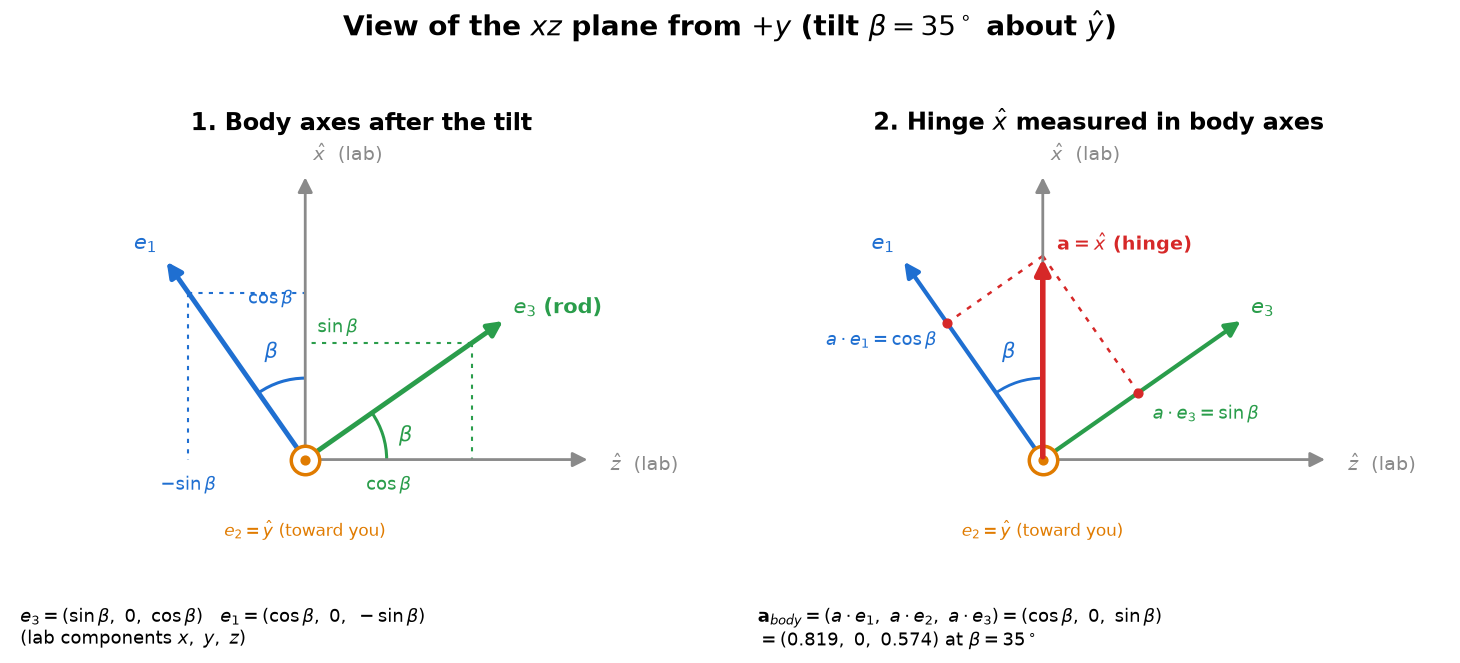

In [5]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.patches import Arc  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ----------------------------------------------------------------------
# STEP 1: set the tilt and the drawing convention
#   What we have:  tilt beta (rad) about the lab y axis
#   What we want:  e1, e3 (body axes) as arrows in the xz plane seen from +y
#   Why:           viewed from +y, z points right and x points up, and a positive
#                  rotation about y is counterclockwise (z turns toward x).
#                  A vector with lab components (x, z) is drawn at (z, x).
#   e3 = (x: sin b, z: cos b)  -> drawn at ( cos b,  sin b)
#   e1 = (x: cos b, z: -sin b) -> drawn at (-sin b,  cos b)
# ----------------------------------------------------------------------
BETA_DEG = 35.0
beta = np.radians(BETA_DEG)
c, s = np.cos(beta), np.sin(beta)

e3 = np.array([c, s])
e1 = np.array([-s, c])
z_hat = np.array([1.0, 0.0])
x_hat = np.array([0.0, 1.0])

GRAY = "#8a8a8a"
BLUE = "#1f6fd1"
GREEN = "#2a9d4b"
RED = "#d62828"
ORANGE = "#e07b00"


def arrow(ax, vec, color, lw=3.0, origin=(0.0, 0.0), zorder=5):
    ax.annotate(
        "",
        xy=(origin[0] + vec[0], origin[1] + vec[1]),
        xytext=origin,
        arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=22),
        zorder=zorder,
    )


def dotted(ax, p, q, color=GRAY, lw=1.5):
    ax.plot([p[0], q[0]], [p[1], q[1]], ls=(0, (2, 3)), color=color, lw=lw, zorder=2)


def setup(ax, title):
    ax.set_xlim(-1.45, 2.0)
    ax.set_ylim(-0.95, 1.55)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=17, fontweight="bold", pad=10)
    arrow(ax, 1.4 * z_hat, GRAY, lw=2.0)
    arrow(ax, 1.4 * x_hat, GRAY, lw=2.0)
    ax.text(1.5, -0.02, r"$\hat z$  (lab)", color=GRAY, fontsize=14, va="center")
    ax.text(0.04, 1.47, r"$\hat x$  (lab)", color=GRAY, fontsize=14, ha="left")
    # e2 = y hat points toward the viewer: circle with a dot
    ax.scatter([0], [0], s=420, facecolors="white", edgecolors=ORANGE, linewidths=2.5, zorder=6)
    ax.scatter([0], [0], s=40, color=ORANGE, zorder=7)
    ax.text(0.0, -0.3, r"$e_2=\hat y$ (toward you)", color=ORANGE, fontsize=12,
            ha="center", va="top")


# ----------------------------------------------------------------------
# STEP 2: the figure, two panels
#   Left:  where the tilted body axes land in lab coordinates
#   Right: the hinge x_hat measured along e1 and e3 (shadows, i.e. cosines)
# ----------------------------------------------------------------------
fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 7.4))
fig.suptitle(r"View of the $xz$ plane from $+y$ (tilt $\beta=%d^\circ$ about $\hat y$)" % BETA_DEG,
             fontsize=20, fontweight="bold", y=0.98)

# ---- left panel: body axes in lab coordinates ----
setup(axL, "1. Body axes after the tilt")
arrow(axL, 1.2 * e3, GREEN, lw=3.5)
arrow(axL, 1.2 * e1, BLUE, lw=3.5)
axL.text(*(1.2 * e3 + np.array([0.04, 0.03])), r"$e_3$ (rod)", color=GREEN, fontsize=15, fontweight="bold")
axL.text(*(1.2 * e1 + np.array([-0.04, 0.05])), r"$e_1$", color=BLUE, fontsize=15, fontweight="bold",
         ha="right")

# angle arcs: z -> e3 and x -> e1
axL.add_patch(Arc((0, 0), 0.8, 0.8, theta1=0, theta2=BETA_DEG, color=GREEN, lw=2.2, zorder=4))
axL.text(0.46, 0.09, r"$\beta$", color=GREEN, fontsize=15)
axL.add_patch(Arc((0, 0), 0.8, 0.8, theta1=90, theta2=90 + BETA_DEG, color=BLUE, lw=2.2, zorder=4))
axL.text(-0.2, 0.5, r"$\beta$", color=BLUE, fontsize=15)

# e3 projections onto lab axes
tip3 = e3
dotted(axL, tip3, (tip3[0], 0.0), GREEN)
dotted(axL, tip3, (0.0, tip3[1]), GREEN)
axL.text(tip3[0] * 0.5 + 0.0, -0.08, r"$\cos\beta$", color=GREEN, fontsize=13, ha="center", va="top")
axL.text(0.06, tip3[1] + 0.03, r"$\sin\beta$", color=GREEN, fontsize=13, ha="left", va="bottom")

# e1 projections onto lab axes
tip1 = e1
dotted(axL, tip1, (tip1[0], 0.0), BLUE)
dotted(axL, tip1, (0.0, tip1[1]), BLUE)
axL.text(tip1[0], -0.08, r"$-\sin\beta$", color=BLUE, fontsize=13, ha="center", va="top")
axL.text(-0.06, tip1[1] * 0.5 + 0.38, r"$\cos\beta$", color=BLUE, fontsize=13, ha="right", va="center")

axL.text(-1.4, -0.72,
         r"$e_3=(\sin\beta,\ 0,\ \cos\beta)$   $e_1=(\cos\beta,\ 0,\ -\sin\beta)$" + "\n"
         + r"(lab components $x,\ y,\ z$)",
         fontsize=13, va="top")

# ---- right panel: hinge measured in body axes ----
setup(axR, "2. Hinge $\\hat x$ measured in body axes")
arrow(axR, 1.2 * e3, GREEN, lw=3.0)
arrow(axR, 1.2 * e1, BLUE, lw=3.0)
axR.text(*(1.2 * e3 + np.array([0.04, 0.03])), r"$e_3$", color=GREEN, fontsize=15, fontweight="bold")
axR.text(*(1.2 * e1 + np.array([-0.04, 0.05])), r"$e_1$", color=BLUE, fontsize=15, fontweight="bold",
         ha="right")
arrow(axR, 1.0 * x_hat, RED, lw=4.0, zorder=8)
axR.text(0.07, 1.03, r"$\mathbf{a}=\hat x$ (hinge)", color=RED, fontsize=14, fontweight="bold")

# shadows of a on e1 and e3
foot1 = c * e1
foot3 = s * e3
dotted(axR, x_hat, foot1, RED, lw=1.8)
dotted(axR, x_hat, foot3, RED, lw=1.8)
axR.scatter([foot1[0], foot3[0]], [foot1[1], foot3[1]], s=40, color=RED, zorder=9)
axR.text(foot1[0] - 0.05, foot1[1] - 0.04, r"$a\cdot e_1=\cos\beta$", color=BLUE, fontsize=13,
         ha="right", va="top")
axR.text(foot3[0] + 0.07, foot3[1] - 0.06, r"$a\cdot e_3=\sin\beta$", color=GREEN, fontsize=13,
         ha="left", va="top")

axR.add_patch(Arc((0, 0), 0.8, 0.8, theta1=90, theta2=90 + BETA_DEG, color=BLUE, lw=2.0, zorder=4))
axR.text(-0.2, 0.5, r"$\beta$", color=BLUE, fontsize=15)

axR.text(-1.4, -0.72,
         r"$\mathbf{a}_{body}=(a\cdot e_1,\ a\cdot e_2,\ a\cdot e_3)=(\cos\beta,\ 0,\ \sin\beta)$" + "\n"
         + r"$=(%.3f,\ 0,\ %.3f)$ at $\beta=%d^\circ$" % (c, s, BETA_DEG),
         fontsize=13, va="top")

fig.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.03, wspace=0.05)

# ----------------------------------------------------------------------
# STEP 3: save
# ----------------------------------------------------------------------
path = os.path.join(RESULT_DIR, f"xz_plane_view_{TIMESTAMP}.png")
fig.savefig(path, dpi=150)
print("saved the figure")
plt.show()